## Kalman Filter for Tracking a Vehicle with a Constant Velocity Model

A standalone linear Kalman filter implementation in `jupyter-notebook` that tracks the position $(p_x, p_y)$ and velocity $(v_x, v_y)$ of a vehicle from noisy position measurements (e.g. a lidar or a GPS).

Since both the motion model and the measurement model are linear, no linearization is needed (compare with the Extended Kalman filter in [ekf_sensor_fusion](./ekf_sensor_fusion/EKF.ipynb)).

---

**State vector:**

$$x = \begin{pmatrix} p_x \\ p_y \\ v_x \\ v_y \end{pmatrix}$$

**State dynamics (constant velocity):**

\begin{align}
    p_x' &= p_x + v_x * dt \\
    p_y' &= p_y + v_y * dt \\
    v_x' &= v_x \\
    v_y' &= v_y
\end{align}

$$ x' = F x + \nu, \qquad F = \begin{bmatrix} 1 & 0 & dt & 0 \\ 0 & 1 & 0 & dt \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 1 \end{bmatrix} $$

>where $\nu \sim N(0, Q)$ is the process noise, caused by unknown accelerations $a_x, a_y$ that are assumed to be Gaussian with zero mean and variances $\sigma_{a_x}^2, \sigma_{a_y}^2$.

**Measurement function:**

$$ z = H x + \omega, \qquad H = \begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \end{bmatrix} $$

>where $\omega \sim N(0, R)$ is the measurement noise with $R = \begin{bmatrix} \sigma_{p}^2 & 0 \\ 0 & \sigma_{p}^2 \end{bmatrix}$ (variances, i.e. the *squared* standard deviations).

**Process covariance matrix:**
$$ Q = \begin{pmatrix} \frac{\Delta t^4 \sigma_{a_x}^2}{4}  & 0 & \frac{\Delta t^3 \sigma_{a_x}^2}{2} & 0 \\ 0 & \frac{\Delta t^4 \sigma_{a_y}^2}{4} & 0 & \frac{\Delta t^3 \sigma_{a_y}^2}{2} \\ \frac{\Delta t^3 \sigma_{a_x}^2}{2} & 0 & \Delta t^2 \sigma_{a_x}^2 & 0 \\ 0 & \frac{\Delta t^3 \sigma_{a_y}^2}{2} & 0 & \Delta t^2 \sigma_{a_y}^2 \end{pmatrix} $$

---

### Kalman Filter Algorithm

**Prediction:**
$$ x' = F x $$
$$ P' = FPF^T + Q $$

**Measurement Update:**
$$ y = z − Hx' $$
$$ S = HP' H^T + R $$
$$ K = P' H^T S^{-1} $$
$$ x = x' + Ky $$
$$ P = (I − KH)P' $$

where,

\begin{align}
x &= \text{state vector} \\
F &= \text{state transition matrix} \\
P &= \text{state covariance matrix} \\
Q &= \text{process noise covariance matrix} \\
z &= \text{measurement vector} \\
H &= \text{measurement matrix (maps the state vector into the measurement domain)} \\
y &= \text{residual (difference between the actual measurement ($z$) and the predicted measurement ($Hx'$))}\\
R &= \text{measurement covariance matrix (sensor noise)} \\
S &= \text{innovation covariance (predicted state uncertainty projected into the measurement domain plus sensor noise)} \\
K &= \text{Kalman gain (how much weight is placed on the measurement relative to the prediction)}
\end{align}

### Kalman Filter function

In [1]:
%matplotlib inline

import numpy as np
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = [10, 7]
mpl.rcParams['figure.dpi'] = 72
import matplotlib.pyplot as plt

In [2]:
class KalmanFilter:
  '''
    A class that estimates the state of a linear system given noisy measurements
    using the Kalman Filter algorithm
  '''

  def __init__(self, n):

    self.n = n
    self.I = np.matrix(np.eye(n))
    self.x = None
    self.P = None
    self.F = None
    self.Q = None
    self.H = None
    self.R = None

  def start(self, x, P, F, Q, H, R):

    self.x = x
    self.P = P
    self.F = F
    self.Q = Q
    self.H = H
    self.R = R

  def setQ(self, Q):
    self.Q = Q

  def updateF(self, dt):
    self.F[0, 2], self.F[1, 3] = dt, dt

  def getx(self):
    return self.x

  def getP(self):
    return self.P

  def predict(self):
    ''' Prediction '''
    self.x = self.F * self.x

    ''' A Priori covariance '''
    self.P = self.F * self.P * self.F.T + self.Q

  def update(self, z):

    ''' Residual '''
    y = z - self.H * self.x
    PHt = self.P * self.H.T
    S = self.H * PHt + self.R

    '''Kalman Gain'''
    K = PHt * np.linalg.inv(S)

    ''' Measurement update '''
    self.x = self.x + K * y

    ''' A posteriori covariance '''
    self.P = (self.I - K * self.H) * self.P

In [3]:
def get_Q(dt, std_ax, std_ay):
  '''
  Computes the process noise covariance matrix of the constant velocity model

  Args:
    dt : float - time difference between two measurements in seconds
    std_ax, std_ay : floats - standard deviation of the unknown acceleration in x and y [m/s^2]

  Returns: a 4 x 4 numpy matrix
  '''

  dt2 = dt * dt
  dt3 = dt * dt2
  dt4 = dt * dt3

  var_ax, var_ay = std_ax**2, std_ay**2

  Q = np.matrix([[dt4 * var_ax / 4, 0,                dt3 * var_ax / 2, 0],
                 [0,                dt4 * var_ay / 4, 0,                dt3 * var_ay / 2],
                 [dt3 * var_ax / 2, 0,                dt2 * var_ax,     0],
                 [0,                dt3 * var_ay / 2, 0,                dt2 * var_ay]])

  return Q

### Simulated data

A vehicle starts at the origin and moves with a velocity of about $(1, 0.5)$ m/s that is randomly perturbed by accelerations. A noisy position is measured at every time step.

In [4]:
def simulate(steps, dt, std_ax, std_ay, std_meas, seed = 1):
  '''
  Simulates a vehicle that moves with a constant velocity perturbed by random accelerations

  Args:
    steps : int - number of time steps
    dt : float - time between two steps in seconds
    std_ax, std_ay : floats - standard deviation of the acceleration noise [m/s^2]
    std_meas : float - standard deviation of the position measurement noise [m]
    seed : int - seed of the random number generator

  Returns:
    truths - a steps x 4 numpy array of the true states (px, py, vx, vy)
    measurements - a steps x 2 numpy array of the noisy positions (px, py)
  '''

  rng = np.random.RandomState(seed)

  x = np.array([0., 0., 1., 0.5])
  truths, measurements = [], []

  for _ in range(steps):
    ax, ay = rng.normal(0, std_ax), rng.normal(0, std_ay)

    x = np.array([x[0] + x[2] * dt + 0.5 * ax * dt * dt,
                  x[1] + x[3] * dt + 0.5 * ay * dt * dt,
                  x[2] + ax * dt,
                  x[3] + ay * dt])

    truths.append(x)
    measurements.append(x[:2] + rng.normal(0, std_meas, 2))

  return np.array(truths), np.array(measurements)

In [5]:
def get_state_estimations(kf, measurements, dt, std_ax, std_ay):
  '''
  Calculates all state estimations given a KalmanFilter instance and position measurements

  Args:
    kf - an instance of a KalmanFilter() class that is already started
    measurements - a steps x 2 numpy array of position measurements
    dt, std_ax, std_ay : floats - time step and acceleration noise used to build the process noise

  Returns: a steps x 4 numpy array of the estimated states (px, py, vx, vy)
  '''

  state_estimations = []

  for z in measurements:

    kf.updateF(dt)
    kf.setQ(get_Q(dt, std_ax, std_ay))
    kf.predict()
    kf.update(np.matrix(z).T)

    state_estimations.append(np.array(kf.getx()).flatten())

  return np.array(state_estimations)

def get_RMSE(predictions, truths):
  '''
  Computes the root mean square error (RMSE) of every state variable

  Args:
    predictions, truths - steps x 4 numpy arrays

  Returns: a numpy array with the RMSE of px, py, vx, vy
  '''
  return np.sqrt(np.mean((predictions - truths)**2, axis = 0))

In [6]:
dt = 0.1             # time between two measurements [s]
std_ax = 0.5         # standard deviation of the acceleration in x [m/s^2]
std_ay = 0.5         # standard deviation of the acceleration in y [m/s^2]
std_meas = 0.5       # standard deviation of the position measurement, applies for x and y [m]

truths, measurements = simulate(300, dt, std_ax, std_ay, std_meas)

''' R - Measurement covariance matrix (variances = squared standard deviations) '''
R = np.matrix([[std_meas**2, 0],
               [0,           std_meas**2]])

''' H - Measurement matrix '''
H = np.matrix([[1, 0, 0, 0],
               [0, 1, 0, 0]])

''' P - Initial state covariance matrix, large velocity uncertainty since velocity is never measured '''
P = np.matrix(np.diag([std_meas**2, std_meas**2, 10., 10.]))

''' Q - Process noise matrix '''
Q = get_Q(dt, std_ax, std_ay)

F = np.matrix(np.eye(4))

''' The filter is started with the first measurement and an unknown (zero) velocity '''
x = np.matrix([[measurements[0, 0]], [measurements[0, 1]], [0.], [0.]])

kf = KalmanFilter(4)
kf.start(x, P, F, Q, H, R)

state_estimations = get_state_estimations(kf, measurements[1:], dt, std_ax, std_ay)
state_estimations = np.vstack([np.array(x).flatten(), state_estimations])

px, py, vx, vy = get_RMSE(state_estimations, truths)
rx, ry = get_RMSE(measurements, truths[:, :2])

print("-------------------------------------------------------------------------------")
print('{:15s} | {:8.3f} | {:8.3f} |'.format("MEASUREMENT RMSE:", rx, ry))
print('{:15s} | {:8.3f} | {:8.3f} | {:8.3f} | {:8.3f} |'.format("FILTER RMSE:", px, py, vx, vy))
print("-------------------------------------------------------------------------------")

-------------------------------------------------------------------------------
MEASUREMENT RMSE: |    0.479 |    0.478 |
FILTER RMSE:    |    0.206 |    0.176 |    0.227 |    0.273 |
-------------------------------------------------------------------------------


### Plot of position $p_x$, $p_y$

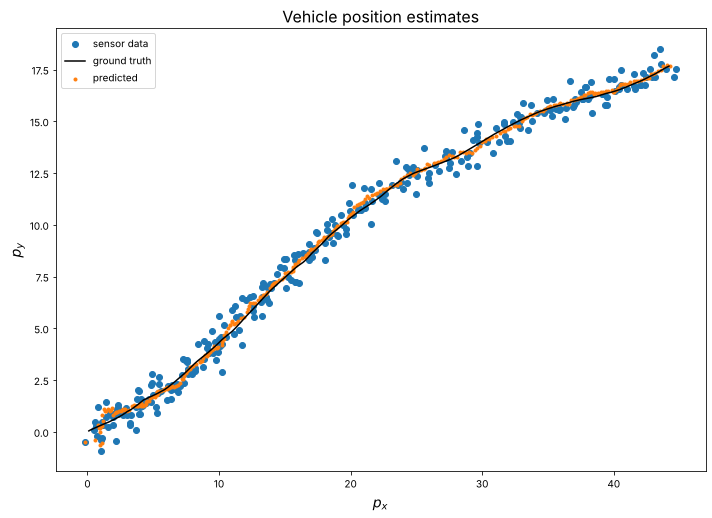

In [7]:
plt.scatter(measurements[:, 0], measurements[:, 1], label="sensor data", marker="o")
plt.plot(truths[:, 0], truths[:, 1], label="ground truth", color="k")
plt.scatter(state_estimations[:, 0], state_estimations[:, 1], label="predicted", marker=".")

plt.xlabel('$p_x$', fontsize=14)
plt.ylabel('$p_y$', fontsize=14)

plt.legend()
plt.tight_layout()
plt.title('Vehicle position estimates', fontsize=16)
plt.show()

### Plot of velocity $v_x$, $v_y$

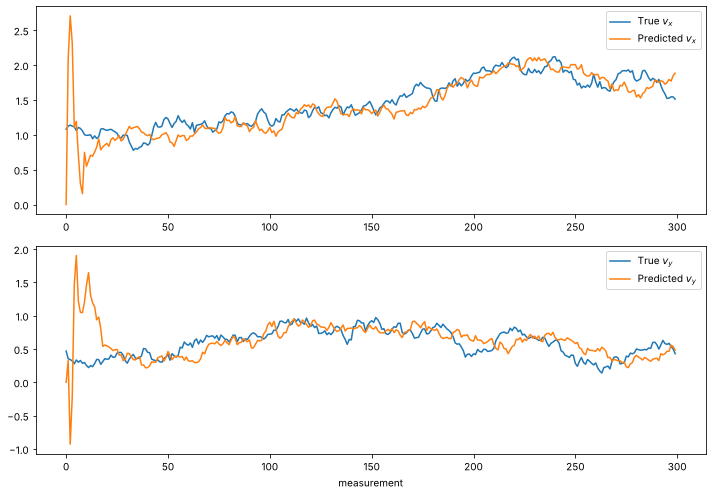

In [8]:
fig, ax = plt.subplots(2)

ax[0].plot(truths[:, 2], label="True $v_x$")
ax[0].plot(state_estimations[:, 2], label="Predicted $v_x$")
ax[0].legend(loc='upper right')

ax[1].plot(truths[:, 3], label="True $v_y$")
ax[1].plot(state_estimations[:, 3], label="Predicted $v_y$")
ax[1].legend(loc='upper right')
ax[1].set_xlabel('measurement')

fig.tight_layout()
plt.show()

## References:

- R. E. Kalman, "A New Approach to Linear Filtering and Prediction Problems," Journal of Basic Engineering, 82(1), 1960, pp. 35-45.

- https://github.com/rlabbe/Kalman-and-Bayesian-Filters-in-Python